## Open Tools, Open Sky
### Doing LSST Science with Public Rubin Data & LINCC Frameworks
#### Latest update: Jorge I. Zuluaga

## Reading and understanding VRO observations submitted to MPC

Data source is: https://b612.ai/rubin-mpc-downloads/

In [25]:
from util import *
import pandas as pd
import pyarrow.parquet as pq
from IPython.display import display
import matplotlib.pyplot as plt
import requests

# Macros
DEG = np.pi / 180
RAD = 1 / DEG

# Directories
!mkdir -p data figures
fig_dir='figures/'
data_dir='data/'

# Reload util.py routines
%load_ext autoreload 
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


Data file and schema:

In [26]:
data_file = data_dir + 'obs_sbn_X05_full.parquet'
columns = pq.read_schema(data_file).names
print_list(columns)

id, trksub, trkid, obsid, submission_id, submission_block_id, obs80, status,
ref, healpix, permid, provid, artsat, mode, stn, trx, rcv, sys, ctr, pos1, pos2,
pos3, poscov11, poscov12, poscov13, poscov22, poscov23, poscov33, prog, obstime,
ra, dec, rastar, decstar, obscenter, deltara, deltadec, dist, pa, rmsra, rmsdec,
rmsdist, rmspa, rmscorr, delay, rmsdelay, doppler, rmsdoppler, astcat, mag,
rmsmag, band, photcat, photap, nucmag, logsnr, seeing, exp, rmsfit, com, frq,
disc, subfrm, subfmt, prectime, precra, precdec, unctime, notes, remarks,
deprecated, localuse, nstars, prev_desig, prev_ref, rmstime, created_at,
updated_at, trkmpc, orbit_id, designation_asterisk, shapeocc, obssubid,
replacesobsid, group_id, vel1, fltr, vel3, vel2, obstime_text


Importing parquet since it is binary and reading is faster:

In [27]:
df_sel = pd.read_parquet(
    data_file,
    columns=['obsid', 'ra', 'dec', 'mag'],
    # filters=[('band', '==', 'r')]
)
df_sel.info(), df_sel.memory_usage(deep=True).sum()/1024**2

<class 'pandas.DataFrame'>
RangeIndex: 8078546 entries, 0 to 8078545
Data columns (total 4 columns):
 #   Column  Dtype
---  ------  -----
 0   obsid   str  
 1   ra      str  
 2   dec     str  
 3   mag     str  
dtypes: str(4)
memory usage: 647.6 MB


(None, np.float64(647.5586929321289))

Convert to numeric:

In [28]:
df_sel[['ra', 'dec', 'mag']] = df_sel[['ra', 'dec', 'mag']].apply(pd.to_numeric, errors='coerce')

### Observations location

Load ecliptic and galactic equator points:

In [29]:
ecl_coords, gal_coords = ecl_gal()

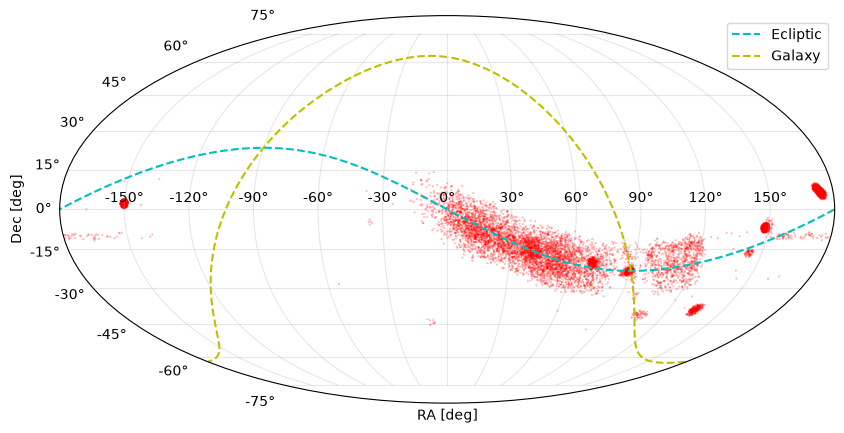

In [30]:
sample = df_sel.sample(10000)
fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(projection='mollweide')
ax.scatter(f2m(sample['ra'])*DEG, sample['dec']*DEG, s=sample['mag']*0.01, alpha=0.3, c='r')
ax.plot(*split_mollweide(ecl_coords[0], ecl_coords[1]), 'c--', label='Ecliptic')
ax.plot(*split_mollweide(gal_coords[0], gal_coords[1]), 'y--', label='Galaxy')
ax.legend()
ax.set_xlabel('RA [deg]')
ax.set_ylabel('Dec [deg]')
ax.grid(alpha=0.3)
fig.savefig(fig_dir + 'scatter-observations-map.png')


Density of observations:

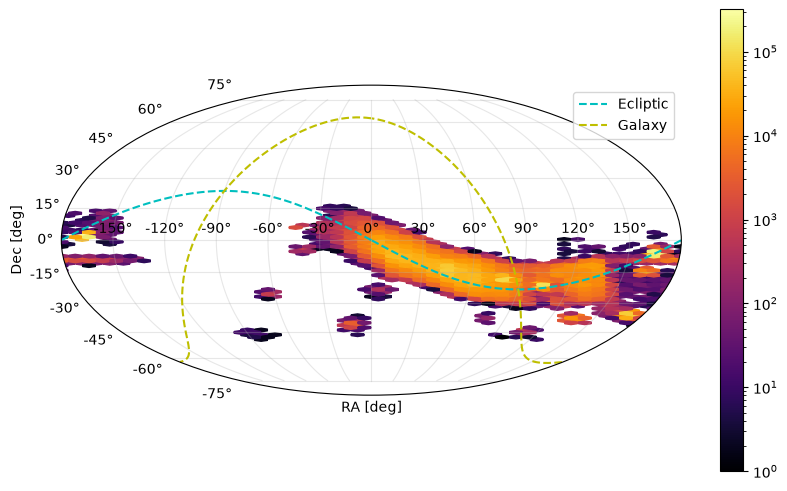

In [31]:
fig = plt.figure(figsize=(10, 6))
ax = fig.add_subplot(projection='mollweide')

hb = ax.hexbin(f2m(df_sel['ra'])*DEG, df_sel['dec']*DEG, gridsize=50, bins='log', cmap='inferno')
fig.colorbar(hb)

ax.plot(*split_mollweide(ecl_coords[0], ecl_coords[1]), 'c--', label='Ecliptic')
ax.plot(*split_mollweide(gal_coords[0], gal_coords[1]), 'y--', label='Galaxy')
ax.legend()

ax.set_xlabel('RA [deg]')
ax.set_ylabel('Dec [deg]')
ax.grid(alpha=0.3)
fig.savefig(fig_dir + 'hexbin-observations-map.png')


## Get data from sbdb

We want to get all data from families of asteroids from the JPL SBDB:

In [32]:
url = 'https://ssd-api.jpl.nasa.gov/sbdb_query.api'

The params we want to get are:

In [33]:
# All fields in: https://ssd-api.jpl.nasa.gov/doc/sbdb_query.html
fields = [
    'pdes', 'full_name', 
    'a', 'e', 'i', 'om', 'w', 'ma', 'epoch', 'data_arc',
    'H', 'diameter', 'class'
]
# Group and classes: https://ssd-api.jpl.nasa.gov/doc/sbdb_filter.html
params = {
    'fields': ','.join(fields),
    # 'sb-group': 'neo',
    'sb-class': 'ATE'
    #'limit': '10'
}

Get the data:

In [34]:
response = requests.get(url, params=params)
response.raise_for_status()
data = response.json()
df = pd.DataFrame(data['data'], columns=data['fields'])
df

,pdes,full_name,a,e,i,om,w,ma,epoch,data_arc,H,diameter,class
0,2062,2062 Aten (1976 AA),0.967,0.1829,18.94,108.53,148.07,239.96,2461200.5,23339,17.11,1.1,ATE
1,2100,2100 Ra-Shalom (1978 RA),0.832,0.4365,15.76,170.76,356.08,148.84,2461200.5,18599,16.24,2.3,ATE
2,2340,2340 Hathor (1976 UA),0.8437,0.4500,5.86,211.21,40.20,96.29,2461200.5,16477,20.41,0.3,ATE
3,3362,3362 Khufu (1984 QA),0.9895,0.4685,9.92,152.40,55.09,240.65,2461200.5,7394,18.52,0.7,ATE
4,3554,3554 Amun (1986 EB),0.9739,0.2805,23.36,358.59,359.42,121.80,2461200.5,12044,15.91,3.341,ATE
...,...,...,...,...,...,...,...,...,...,...,...,...,...
3474,2026 TC6,(2026 TC6),0.7464,0.4596,8.00,16.93,157.25,42.40,2461200.5,3,26.10,NaN,ATE
3475,2026 TJ6,(2026 TJ6),0.9898,0.1361,9.88,5.08,244.51,347.97,2461200.5,4,26.25,NaN,ATE
3476,2026 TP6,(2026 TP6),0.9774,0.3466,3.56,22.62,112.06,155.88,2461200.5,6,27.29,NaN,ATE
3477,2026 TS35,(2026 TS35),0.9847,0.3141,3.02,10.17,236.02,93.82,2461321.5,4,25.85,NaN,ATE
